In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
df = sns.load_dataset("penguins")

In [ ]:
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [ ]:
df.shape

(344, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [ ]:
df.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [ ]:
df['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


Se nos pide utilizar la función de activación sigmoide con la función de Perdida Binary-Cross Entropy, que son para una clasificación binaria, y en nuestro dataset original son 3 tipos de pinguinos, entonces solo nos quedaremos con 2 especies para poder aplicar estas funciones correctamente

In [ ]:
# Nos quedamos solo con las especies Adelie y Chinstrap
df = df[df['species'].isin(['Adelie', 'Chinstrap'])]

Convertimos la variable objetivo que es species a 0 y 1 (numérica)

In [ ]:
df['species'] = df['species'].map({'Adelie': 0, 'Chinstrap': 1})

In [ ]:
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,0,Torgersen,39.1,18.7,181.0,3750.0,Male
1,0,Torgersen,39.5,17.4,186.0,3800.0,Female
2,0,Torgersen,40.3,18.0,195.0,3250.0,Female
3,0,Torgersen,NaN,NaN,NaN,NaN,NaN
4,0,Torgersen,36.7,19.3,193.0,3450.0,Female


In [ ]:
df['species'].value_counts()

,count
species,
0,152
1,68


Observemos que nuestra variable objetivo está desbalanceada, ya que hay más datos (152) de la especie 0 Adelie que la especie 1 Chinstrap (68), por lo que al separar nuestros datos en trin y test debemos estratificar

Representa aproximadamente 69% de la especie 0 y aproximadamente 31% de la especie 1

In [ ]:
X = df.drop("species", axis=1)
y = df["species"]

In [ ]:
X.head(3)

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Torgersen,40.3,18.0,195.0,3250.0,Female


In [ ]:
X.shape

(220, 6)

In [ ]:
y.head(3)

,species
0,0
1,0
2,0


In [ ]:
y.shape

(220,)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

In [ ]:
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [ ]:
X_train.shape

(176, 6)

In [ ]:
X_test.shape

(44, 6)

In [ ]:
columnas_numericas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

for col in columnas_numericas:
    media_col_train = X_train[col].mean()
    X_train[col] = X_train[col].fillna(media_col_train)
    X_test[col] = X_test[col].fillna(media_col_train)

In [ ]:
moda_sex_train = X_train["sex"].mode().iloc[0]
X_train["sex"] = X_train["sex"].fillna(moda_sex_train)
X_test["sex"] = X_test["sex"].fillna(moda_sex_train)

In [ ]:
X_train.isna().sum()

,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [ ]:
X_test.isna().sum()

,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [ ]:
X_train['island'].value_counts()

,count
island,
Dream,98
Torgersen,43
Biscoe,35


In [ ]:
X_test['island'].value_counts()

,count
island,
Dream,26
Biscoe,9
Torgersen,9


In [ ]:
# get_dummies
X_train = pd.get_dummies(X_train, columns=["island", "sex"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["island", "sex"], dtype=int)

In [ ]:
""" # OneHotEncoder
for column in ["island", "sex"]:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    encoder.fit(X_train[[column]])

    X_train = pd.concat([
        X_train.drop(column, axis=1),
        pd.DataFrame(
            encoder.transform(X_train[[column]]),
            columns=map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis=1
    )

    X_test = pd.concat([
        X_test.drop(column, axis=1),
        pd.DataFrame(
            encoder.transform(X_test[[column]]),
            columns=map(lambda x: column + "_" + str(x), encoder.categories_[0])
        )],
        axis=1
    )
"""

' # OneHotEncoder\nfor column in ["island", "sex"]:\n    encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")\n    encoder.fit(X_train[[column]])\n    \n    X_train = pd.concat([\n        X_train.drop(column, axis=1),\n        pd.DataFrame(\n            encoder.transform(X_train[[column]]),\n            columns=map(lambda x: column + "_" + str(x), encoder.categories_[0])\n        )],\n        axis=1\n    )\n    \n    X_test = pd.concat([\n        X_test.drop(column, axis=1),\n        pd.DataFrame(\n            encoder.transform(X_test[[column]]),\n            columns=map(lambda x: column + "_" + str(x), encoder.categories_[0])\n        )],\n        axis=1\n    )\n'

In [ ]:
X_train.head(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,40.9,16.6,187.0,3200.0,0,1,0,1,0
1,41.8,19.4,198.0,4450.0,0,0,1,0,1
2,41.1,17.5,190.0,3900.0,0,1,0,0,1


In [ ]:
X_train.columns

Index(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g',
       'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_Female',
       'sex_Male'],
      dtype='object')

In [ ]:
X_test.head(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,54.2,20.8,201.0,4300.0,0,1,0,0,1
1,46.2,17.5,187.0,3650.0,0,1,0,1,0
2,32.1,15.5,188.0,3050.0,0,1,0,1,0


In [ ]:
X_test.columns

Index(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g',
       'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_Female',
       'sex_Male'],
      dtype='object')

In [ ]:
for numeric_column in columnas_numericas:
    scaler = StandardScaler()
    scaler.fit(X_train[[numeric_column]])
    X_train[numeric_column] = scaler.transform(X_train[[numeric_column]])
    X_test[numeric_column] = scaler.transform(X_test[[numeric_column]])

In [ ]:
X_train.shape

(176, 9)

In [ ]:
X_test.shape

(44, 9)

In [ ]:
# semilla
tf.keras.utils.set_random_seed(42)

In [ ]:
# 1. Diseñar la red neuronal
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=1, activation="sigmoid")
])

In [ ]:
# 2. Configurar la red neuronal
model.compile(
    loss = "binary_crossentropy",
    optimizer = tf.keras.optimizers.SGD(learning_rate=0.01),
    metrics = ["accuracy", tf.keras.metrics.F1Score(threshold=0.5)] #accuracy y f1
)

In [ ]:
# 3. Entrenar el modelo
model.fit(X_train, y_train, epochs=100, verbose=1)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.6193 - f1_score: 0.5180 - loss: 0.6596
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6307 - f1_score: 0.5255 - loss: 0.6475 
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6420 - f1_score: 0.5401 - loss: 0.6358
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6477 - f1_score: 0.5441 - loss: 0.6244
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6534 - f1_score: 0.5481 - loss: 0.6133
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6534 - f1_score: 0.5481 - loss: 0.6024
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6591 - f1_score: 0.5522 - loss: 0.5919
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6705 - f1_score: 0.5606 - loss: 0.5817
Epoch 9/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6875 - f1_score: 0.5802 - loss: 0.5718 
Epoch 10/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6875 -

In [ ]:
# 4. Predecir
y_pred_probabilidades = model.predict(X_test)

# ajuste
y_pred = (y_pred_probabilidades > 0.5).astype(int)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


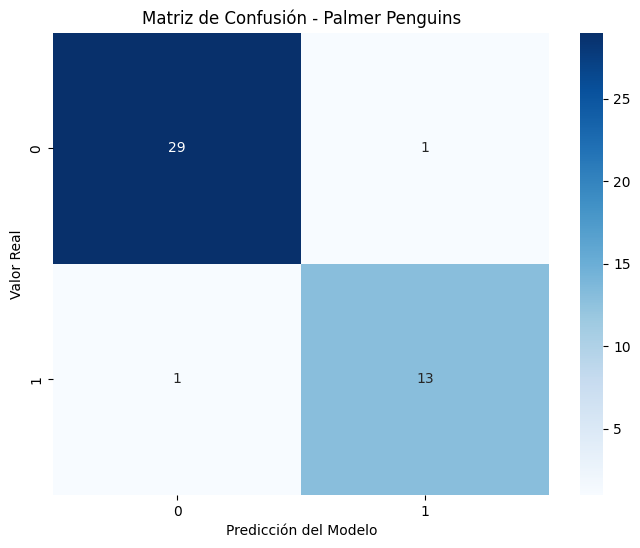

In [ ]:
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión - Palmer Penguins')
plt.show()

In [ ]:
# 5. Evaluación del modelo
loss, accuracy, f1_score = model.evaluate(X_test, y_test, verbose=0)

print(f"Pérdida (Loss): {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1: {f1_score:.4f}")

Pérdida (Loss): 0.2345
Accuracy: 0.9545
F1: 0.9286
